<a href="https://colab.research.google.com/github/kennedy336/Machine-Learning-and-Deep-learning-mini-Projects/blob/main/Car_RienforcementLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import random
from collections import deque

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib import animation
from IPython.display import HTML

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

In [3]:
# Grille du circuit (en nombre de cases)
W = 24                     # largeur de la grille  -> calculée ensuite pour les murs
H = 24                     # hauteur de la grille
X = W // 6                 # unité de base "X" du croquis

# --- Rectangles des murs, calculés à partir de W, H, X (comme sur le croquis) ---
# format (x0, y0, largeur, hauteur)
WALL_TOP = (0, 0, W, X)                 # bande du haut, toute la largeur, hauteur X
WALL_BR  = (X, 2 * X, W - X, H - 2 * X) # bloc bas-droit : largeur = W - X, hauteur = H - 2X

START = (X // 2, H - 1)                 # bas du couloir gauche
GOAL  = (W - 1, X + X // 2)             # bout du couloir horizontal, à droite

MAX_STEPS = 200                         # nb de pas max avant d'arrêter un épisode


def is_wall(col, row):
    if row < X:
        return True                      # bande du haut
    if row >= 2 * X and col >= X:
        return True                      # bloc bas-droit
    return False


def in_bounds(col, row):
    return 0 <= col < W and 0 <= row < H


ACTIONS = [(0, -1), (0, 1), (-1, 0), (1, 0)]   # haut, bas, gauche, droite
n_actions = len(ACTIONS)

print("Départ:", START, "| Objectif:", GOAL, "| Unité X:", X)

Départ: (2, 23) | Objectif: (23, 6) | Unité X: 4


In [4]:
class CarEnv:
    """
    Environnement de conduite simplifié sur grille.
    Etat = position normalisée + direction vers l'objectif + capteurs de murs
           (haut/bas/gauche/droite) -> équivalent des "rendements récents" du trading.
    Action = 0 (haut), 1 (bas), 2 (gauche), 3 (droite).
    Récompense = -1 par pas (favorise le chemin le plus court), -5 si mur/bord,
                 +100 en atteignant l'objectif.
    """

    def __init__(self):
        self.position = START
        self.steps = 0

    def reset(self):
        self.position = START
        self.steps = 0
        return self._get_state()

    def _get_state(self):
        col, row = self.position
        gx, gy = GOAL

        sensors = []
        for dcol, drow in ACTIONS:
            ncol, nrow = col + dcol, row + drow
            wall = 1.0 if (not in_bounds(ncol, nrow) or is_wall(ncol, nrow)) else 0.0
            sensors.append(wall)

        pos_norm = [col / W, row / H]
        delta_goal = [(gx - col) / W, (gy - row) / H]

        return np.array(pos_norm + delta_goal + sensors, dtype=np.float32)

    def step(self, action):
        col, row = self.position
        dcol, drow = ACTIONS[action]
        ncol, nrow = col + dcol, row + drow

        if not in_bounds(ncol, nrow) or is_wall(ncol, nrow):
            reward = -5.0                       # collision -> on reste sur place
        elif (ncol, nrow) == GOAL:
            self.position = (ncol, nrow)
            reward = 100.0
        else:
            self.position = (ncol, nrow)
            reward = -1.0

        self.steps += 1
        done = (self.position == GOAL) or (self.steps >= MAX_STEPS)
        return self._get_state(), float(reward), done, {}


env = CarEnv()
state_dim = len(env.reset())
print("Dimension de l'état (entrée du réseau):", state_dim)

Dimension de l'état (entrée du réseau): 8


In [5]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, n_actions):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, n_actions),
        )

    def forward(self, x):
        return self.net(x)


policy_net = QNetwork(state_dim, n_actions)
target_net = QNetwork(state_dim, n_actions)
target_net.load_state_dict(policy_net.state_dict())
optimizer = optim.Adam(policy_net.parameters(), lr=1e-3)

buffer = deque(maxlen=20000)
gamma, batch_size = 0.95, 64
epsilon, epsilon_min, epsilon_decay = 1.0, 0.05, 0.995
target_update_every = 10
n_episodes = 6000

In [6]:
def select_action(state, eps):
    if random.random() < eps:
        return random.randint(0, n_actions - 1)          # exploration
    with torch.no_grad():
        q_values = policy_net(torch.tensor(state, dtype=torch.float32))
        return int(torch.argmax(q_values).item())          # exploitation


def train_step():
    if len(buffer) < batch_size:
        return
    batch = random.sample(buffer, batch_size)
    s, a, r, s2, d = zip(*batch)
    s = torch.tensor(np.array(s), dtype=torch.float32)
    a = torch.tensor(a).unsqueeze(1)
    r = torch.tensor(np.array(r), dtype=torch.float32)
    s2 = torch.tensor(np.array(s2), dtype=torch.float32)
    d = torch.tensor(d, dtype=torch.float32)

    q_pred = policy_net(s).gather(1, a).squeeze(1)
    with torch.no_grad():
        q_next = target_net(s2).max(1)[0]
        q_target = r + gamma * q_next * (1 - d)

    loss = F.mse_loss(q_pred, q_target)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

In [7]:
history = []
for episode in range(n_episodes):
    state = env.reset()
    done, total_reward = False, 0.0
    while not done:
        action = select_action(state, epsilon)
        next_state, reward, done, _ = env.step(action)
        buffer.append((state, action, reward, next_state, float(done)))
        state = next_state
        total_reward += reward
        train_step()

    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    if episode % target_update_every == 0:
        target_net.load_state_dict(policy_net.state_dict())

    history.append(total_reward)

    if episode % 20 == 0:
        print(f"Episode {episode} | récompense cumulée = {total_reward:.1f} | eps = {epsilon:.2f}")

print(f"\nRécompense moyenne (30 derniers épisodes) : {np.mean(history[-30:]):.1f}")

Episode 0 | récompense cumulée = -352.0 | eps = 0.99
Episode 20 | récompense cumulée = -332.0 | eps = 0.90
Episode 40 | récompense cumulée = -304.0 | eps = 0.81
Episode 60 | récompense cumulée = -264.0 | eps = 0.74
Episode 80 | récompense cumulée = -264.0 | eps = 0.67
Episode 100 | récompense cumulée = -260.0 | eps = 0.60
Episode 120 | récompense cumulée = -134.0 | eps = 0.55
Episode 140 | récompense cumulée = -248.0 | eps = 0.49
Episode 160 | récompense cumulée = -16.0 | eps = 0.45
Episode 180 | récompense cumulée = -44.0 | eps = 0.40
Episode 200 | récompense cumulée = 9.0 | eps = 0.37
Episode 220 | récompense cumulée = -8.0 | eps = 0.33
Episode 240 | récompense cumulée = 15.0 | eps = 0.30
Episode 260 | récompense cumulée = 37.0 | eps = 0.27
Episode 280 | récompense cumulée = 37.0 | eps = 0.24
Episode 300 | récompense cumulée = 48.0 | eps = 0.22
Episode 320 | récompense cumulée = 31.0 | eps = 0.20
Episode 340 | récompense cumulée = 46.0 | eps = 0.18
Episode 360 | récompense cumulée = 

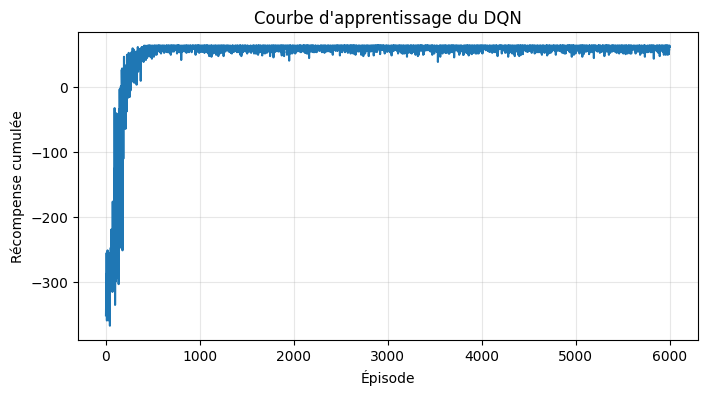

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(history)
plt.xlabel("Épisode")
plt.ylabel("Récompense cumulée")
plt.title("Courbe d'apprentissage du DQN")
plt.grid(alpha=0.3)
plt.show()

In [9]:
def draw_track(ax):
    ax.clear()
    ax.set_xlim(0, W)
    ax.set_ylim(0, H)
    ax.invert_yaxis()             # ligne 0 en haut, comme sur le croquis
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])

    # murs -> VERT (zones hachurées rouges du croquis)
    ax.add_patch(patches.Rectangle((WALL_TOP[0], WALL_TOP[1]), WALL_TOP[2], WALL_TOP[3],
                                    facecolor="#2e8b3d", edgecolor="#1d5e27", linewidth=2))
    ax.add_patch(patches.Rectangle((WALL_BR[0], WALL_BR[1]), WALL_BR[2], WALL_BR[3],
                                    facecolor="#2e8b3d", edgecolor="#1d5e27", linewidth=2))

    # objectif
    gx, gy = GOAL
    ax.add_patch(patches.Circle((gx + 0.5, gy + 0.5), 0.35,
                                 facecolor="gold", edgecolor="#b8860b", linewidth=2))
    ax.text(gx + 0.5, gy + 0.5, "🏁", ha="center", va="center", fontsize=9)


def draw_car(ax, position, car_patch=None):
    col, row = position
    if car_patch is None:
        car_patch = patches.Rectangle((col + 0.1, row + 0.1), 0.8, 0.8,
                                       facecolor="#1565c0", edgecolor="#0d3d75", linewidth=2)
        ax.add_patch(car_patch)
    else:
        car_patch.set_xy((col + 0.1, row + 0.1))
    return car_patch


def extract_path(max_steps=MAX_STEPS):
    """Suit la politique apprise (gloutonne, eps=0) depuis START."""
    state = env.reset()
    path = [env.position]
    for _ in range(max_steps):
        action = select_action(state, 0.0)          # eps=0 -> toujours la meilleure action
        state, _, done, _ = env.step(action)
        path.append(env.position)
        if done:
            break
    return path


path = extract_path()
print(f"Trajet appris : {len(path) - 1} pas | objectif atteint : {path[-1] == GOAL}")

Trajet appris : 38 pas | objectif atteint : True


In [10]:
# Animation de la voiture (jouable directement dans le notebook)
fig, ax = plt.subplots(figsize=(6, 6))
draw_track(ax)
car_patch = draw_car(ax, path[0])


def update(frame):
    draw_car(ax, path[frame], car_patch)
    return car_patch,


anim = animation.FuncAnimation(fig, update, frames=len(path), interval=150, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())

/tmp/ipykernel_741/3615678668.py:12: UserWarning: Glyph 127937 (\N{CHEQUERED FLAG}) missing from font(s) DejaVu Sans.
  anim = animation.FuncAnimation(fig, update, frames=len(path), interval=150, blit=True)
/tmp/ipykernel_741/3615678668.py:14: UserWarning: Glyph 127937 (\N{CHEQUERED FLAG}) missing from font(s) DejaVu Sans.
  HTML(anim.to_jshtml())
